In [1]:
import pandas as pd
import re
import string
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "job_train.csv"
)

df.head()

,title,location,description,requirements,telecommuting,has_company_logo,has_questions,fraudulent
0,Architect (Middleware - MQ) - Kuwait,"KW, KU,","On behalf of our client, a well known multinat...",-Working technical knowledge of IT systems and...,0,1,0,0
1,Interviewing Now for Sales Rep Positions -- wi...,"US, TX, Corpus Christi","We are Argenta Field Solutions, a rapidly expa...",#NAME?,0,1,0,0
2,Process Controls Staff Engineer - Foxboro I/A ...,"US, TX, USA Southwest",Experienced Process Controls Staff Engineer is...,At least 10 years of degreed professional expe...,0,0,0,0
3,Experienced Telemarketer Wanted - Digital Solu...,"AU, NSW,",If you have a passion for people and love to s...,"Responsibilities - Prospecting, following up a...",0,1,0,0
4,Senior Network Engineer,"GB, ENG, London",As the successful Senior Network Engineer you ...,Essential skills:•Juniper switching/routing/se...,0,1,0,0


In [3]:
df.shape

(8940, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8940 entries, 0 to 8939
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   title             8940 non-null   object
 1   location          8783 non-null   object
 2   description       8939 non-null   object
 3   requirements      7614 non-null   object
 4   telecommuting     8940 non-null   int64 
 5   has_company_logo  8940 non-null   int64 
 6   has_questions     8940 non-null   int64 
 7   fraudulent        8940 non-null   int64 
dtypes: int64(4), object(4)
memory usage: 558.9+ KB


In [5]:
df.isnull().sum()

title                  0
location             157
description            1
requirements        1326
telecommuting          0
has_company_logo       0
has_questions          0
fraudulent             0
dtype: int64

In [6]:
df=df.drop_duplicates()

In [7]:
df.isnull().sum()

title                  0
location             157
description            1
requirements        1308
telecommuting          0
has_company_logo       0
has_questions          0
fraudulent             0
dtype: int64

In [8]:
text_columns = [
    "title",
    "location",
    "description",
    "requirements"
]

for col in text_columns:
    df[col] = df[col].fillna("")

In [9]:
df.isnull().sum()

title               0
location            0
description         0
requirements        0
telecommuting       0
has_company_logo    0
has_questions       0
fraudulent          0
dtype: int64

In [10]:
df["text"] = (
    df["title"] + " " +
    df["location"] + " " +
    df["description"] + " " +
    df["requirements"]
)

In [11]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_text)

In [12]:
df["fraudulent"].value_counts()

fraudulent
0    8389
1     446
Name: count, dtype: int64

In [13]:
X = df["clean_text"]

y = df["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(
    X_train
)

X_test_tfidf = tfidf.transform(
    X_test
)


In [14]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(
    X_train_tfidf,
    y_train
)

y_pred = model.predict(
    X_test_tfidf
)

accuracy_score(
    y_test,
    y_pred
)

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1678
           1       0.56      0.75      0.64        89

    accuracy                           0.96      1767
   macro avg       0.77      0.86      0.81      1767
weighted avg       0.97      0.96      0.96      1767



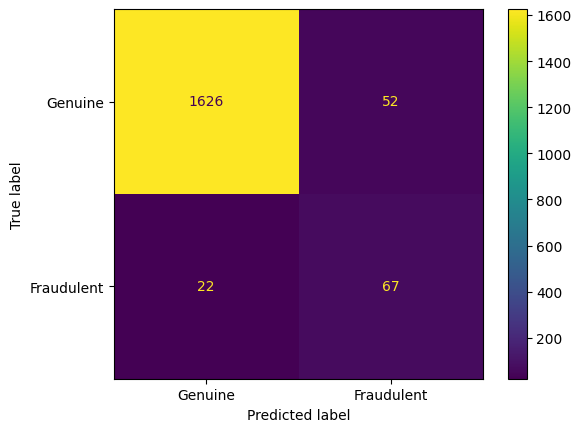

In [15]:
cm = confusion_matrix(
    y_test,
    y_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Genuine",
        "Fraudulent"
    ]
).plot()

plt.show()

In [16]:
joblib.dump(
    model,
    "fake_job_model.pkl"
)
joblib.dump(
    tfidf,
    "tfidf.pkl"
)

['tfidf.pkl']

In [17]:
title = "Work From Home Data Entry"

location = "Remote"

description = """
Earn 50000 per week.
No experience required.
Pay registration fee to start working.
"""

requirements = """
No skills required.
"""


In [18]:
new_job = (
    title + " " +
    location + " " +
    description + " " +
    requirements
)

cleaned_job = clean_text(
    new_job
)

new_job_tfidf = tfidf.transform(
    [cleaned_job]
)

prediction = model.predict(
    new_job_tfidf
)[0]

if prediction == 1:
    print(" Fraudulent Job Posting")
else:
    print(" Genuine Job Posting")

 Fraudulent Job Posting
